# Both pooling vs Stovepipe — PRIM on delta (2 ambulances)


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

RESULTS_PATH = _root / "data_cluster/resource_grid/results.csv"
df = pd.read_csv(RESULTS_PATH)
df = df[df["n_amb_r1_to_ccp"] == 2]
print(f"Loaded {len(df)} runs (2 ambulances)")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate"]
LEVERS = UNCERTAINTIES
MATCH_COLS = ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate"]

def get_policy(df_sub, fac, amb):
    return df_sub[(df_sub["facility_eligibility"] == fac) & (df_sub["ambulance_eligibility"] == amb)]

OUTCOME_COLS = [c for c in df.columns if c.startswith(("death_rate", "mortality_", "median_wait", "frac_", "n_patients"))]
policy_raw = get_policy(df, 1, 1)
stove_raw  = get_policy(df, 0, 0)

policy = policy_raw.groupby(LEVERS)[OUTCOME_COLS].mean().reset_index()
stove  = stove_raw.groupby(LEVERS)[OUTCOME_COLS].mean().reset_index()
policy = policy.sort_values(LEVERS).reset_index(drop=True)
stove  = stove.sort_values(LEVERS).reset_index(drop=True)

assert len(policy) == len(stove), f"Mismatch: {len(policy)} vs {len(stove)}"
assert (policy[LEVERS].values == stove[LEVERS].values).all()

delta = policy["death_rate_T1_BCAS"].values - stove["death_rate_T1_BCAS"].values
print(f"{len(policy)} scenarios")
print(f"Delta: min={delta.min():.4f}, median={np.median(delta):.4f}, mean={delta.mean():.4f}, max={delta.max():.4f}")
print(f"Helps: {(delta < 0).sum()}, Indifferent: {(delta == 0).sum()}, Hurts: {(delta > 0).sum()}")

x = policy[UNCERTAINTIES].astype(float)

def show_tradeoff_highlighted(box, step=None):
    fig = box.show_tradeoff()
    if step is not None:
        traj = box.peeling_trajectory
        if step in traj.index:
            row = traj.loc[step]
            ax = fig.axes[0]
            ax.plot(row["coverage"], row["density"], "o", color="red", markersize=14, zorder=5,
                    markerfacecolor="none", markeredgecolor="red", markeredgewidth=2.5)
    plt.show()


C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Loaded 405600 runs (2 ambulances)
1014 scenarios
Delta: min=-0.7404, median=-0.1036, mean=-0.1347, max=0.3597
Helps: 926, Indifferent: 0, Hurts: 88


## Delta distribution


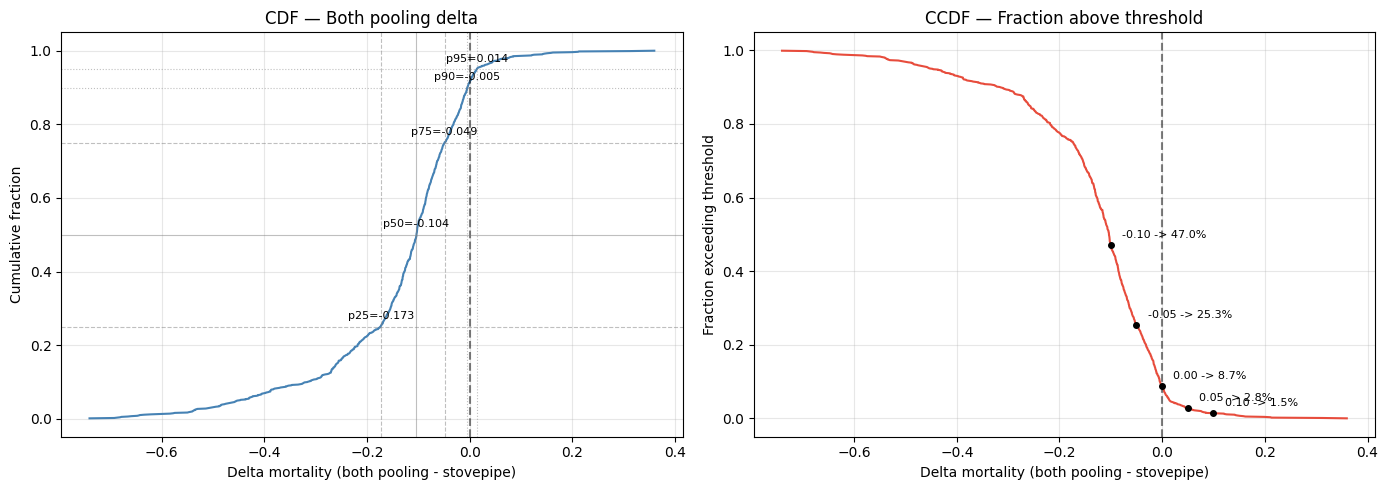

In [2]:
sorted_d = np.sort(delta)
cdf = np.arange(1, len(sorted_d) + 1) / len(sorted_d)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(sorted_d, cdf, color="steelblue", linewidth=1.5)
axes[0].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[0].set_xlabel("Delta mortality (both pooling - stovepipe)")
axes[0].set_ylabel("Cumulative fraction")
axes[0].set_title("CDF — Both pooling delta")
axes[0].grid(True, alpha=0.3)

for p, ls in [(0.25, "--"), (0.50, "-"), (0.75, "--"), (0.90, ":"), (0.95, ":")]:
    val = np.percentile(delta, p * 100)
    axes[0].axhline(p, color="grey", linestyle=ls, alpha=0.5, linewidth=0.8)
    axes[0].axvline(val, color="grey", linestyle=ls, alpha=0.5, linewidth=0.8)
    axes[0].text(val, p + 0.02, f"p{int(p*100)}={val:.3f}", fontsize=8, ha="center")

axes[1].plot(sorted_d, 1 - cdf, color="#e74c3c", linewidth=1.5)
axes[1].axvline(0, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Delta mortality (both pooling - stovepipe)")
axes[1].set_ylabel("Fraction exceeding threshold")
axes[1].set_title("CCDF — Fraction above threshold")
axes[1].grid(True, alpha=0.3)

for t in [-0.10, -0.05, 0.0, 0.05, 0.10]:
    frac = (delta > t).mean()
    axes[1].plot(t, frac, "o", color="black", markersize=4)
    axes[1].annotate(f"{t:.2f} -> {frac:.1%}", (t, frac), textcoords="offset points",
                     xytext=(8, 5), fontsize=8)

plt.tight_layout()
plt.show()


## PRIM — Pooling helps


Target scenarios: 926 / 1014 (91.3%)


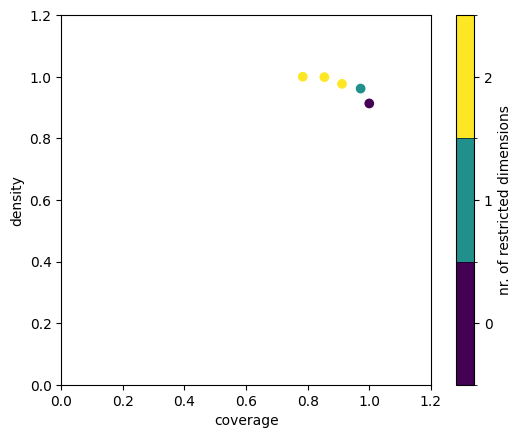

In [3]:
# === Pooling helps: delta < 0 ===
y = delta < 0

print(f"Target scenarios: {y.sum()} / {len(y)} ({y.mean():.1%})")
p_box1 = prim.Prim(x, y, threshold=0.2)
box1 = p_box1.find_box()
box1.show_tradeoff()
plt.show()


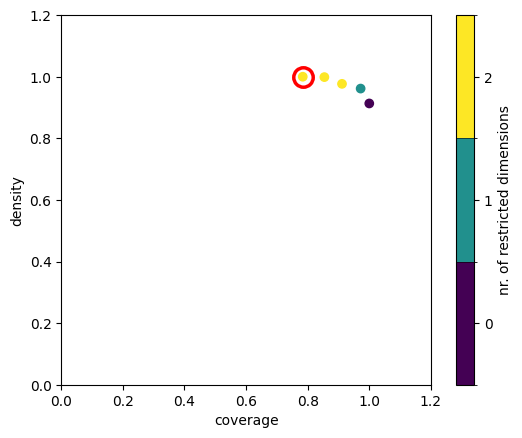

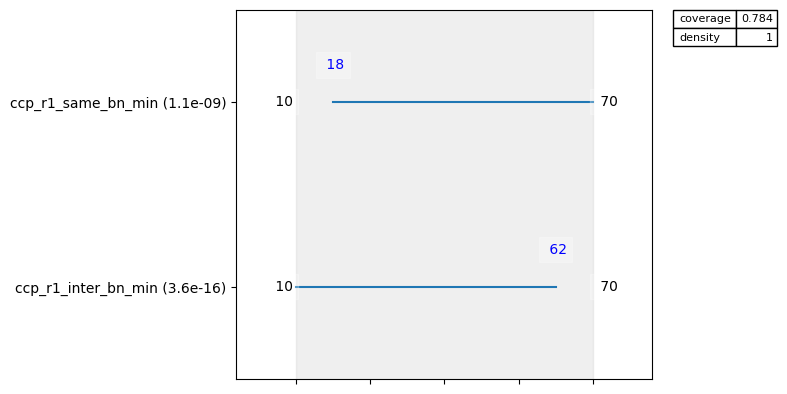

In [22]:
STEP_1 = 4   # e.g. 10, 15, 20

if STEP_1 is not None:
    box1.select(STEP_1)
show_tradeoff_highlighted(box1, step=STEP_1)

box1.inspect(style="graph")
plt.show()


In [23]:
box1.inspect()


coverage      0.784017
density       1.000000
id            4.000000
k           726.000000
mass          0.715976
mean          1.000000
n           726.000000
res_dim       2.000000
Name: 4, dtype: float64

                    box 4                                  
                      min   max      qp value      qp value
ccp_r1_inter_bn_min  10.0  62.5           NaN  3.642857e-16
ccp_r1_same_bn_min   17.5  70.0  1.134441e-09           NaN


[None]

C:\Users\User\AppData\Local\Temp\ipykernel_7392\3306705430.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,


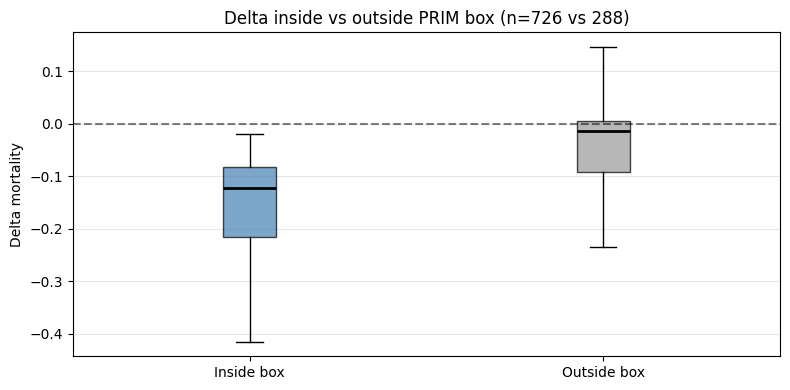

Inside:  n=726, helps=100.0%, hurts=0.0%, median=-0.1233, 95% CI [-0.1307, -0.1146]
Outside: n=288, helps=69.4%, hurts=30.6%, median=-0.0146


In [6]:
from scipy.stats import bootstrap as _bootstrap
_in = delta[box1.yi]
_out = np.delete(delta, box1.yi)

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=2))
bp["boxes"][0].set_facecolor("steelblue"); bp["boxes"][0].set_alpha(0.7)
bp["boxes"][1].set_facecolor("#999999"); bp["boxes"][1].set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title(f"Delta inside vs outside PRIM box (n={len(_in)} vs {len(_out)})")
plt.tight_layout()
plt.show()

_ci_in = _bootstrap((_in,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
print(f"Inside:  n={len(_in)}, helps={(_in<0).mean():.1%}, hurts={(_in>0).mean():.1%}, median={np.median(_in):+.4f}, 95% CI [{_ci_in.low:+.4f}, {_ci_in.high:+.4f}]")
print(f"Outside: n={len(_out)}, helps={(_out<0).mean():.1%}, hurts={(_out>0).mean():.1%}, median={np.median(_out):+.4f}")


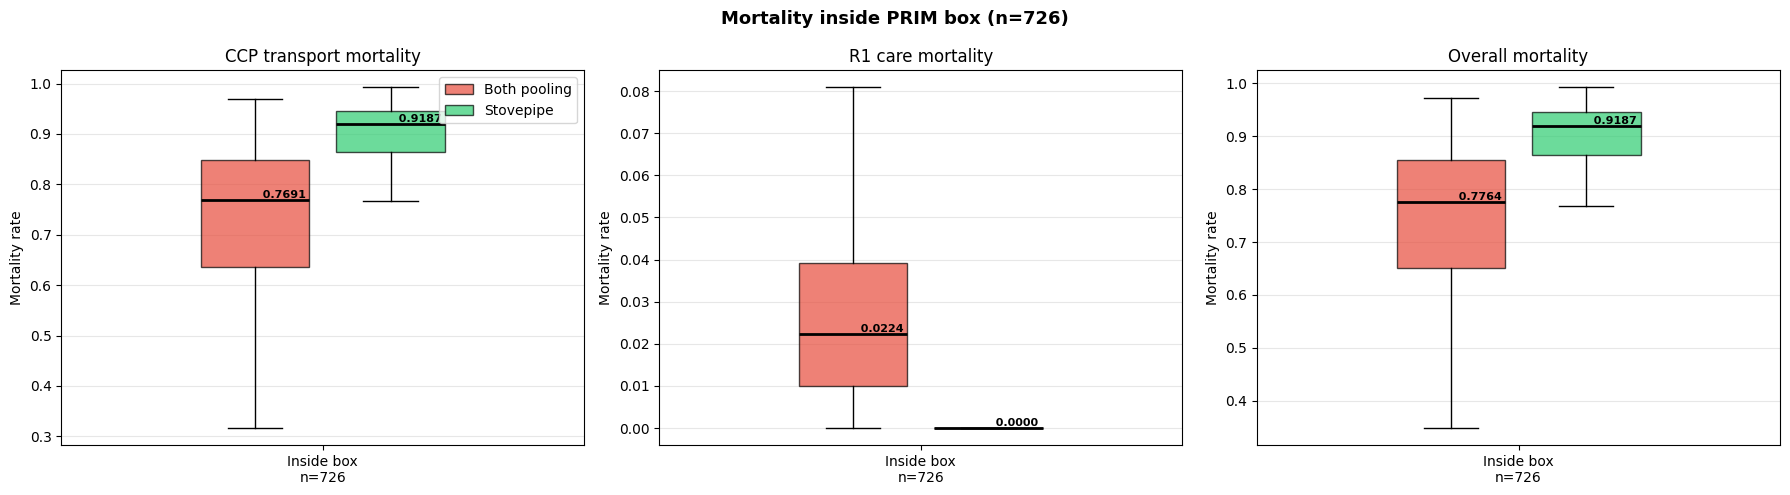

  mortality_ccp_transport_T1: Both pooling=100.0%, Stovepipe=100.0%
  mortality_r1_care_T1: Both pooling=96.7%, Stovepipe=3.0%

Median mortality with 95% CI inside PRIM box (n=726):
  mortality_ccp_transport_T1: Both pooling median=0.7691 CI=[0.7598, 0.7862]
  mortality_ccp_transport_T1: Stovepipe median=0.9187 CI=[0.9051, 0.9228]
  mortality_r1_care_T1: Both pooling median=0.0224 CI=[0.0208, 0.0246]
  mortality_r1_care_T1: Stovepipe median=0.0000 CI=[0.0000, 0.0000]
  death_rate_T1_BCAS: Both pooling median=0.7764 CI=[0.7667, 0.7921]
  death_rate_T1_BCAS: Stovepipe median=0.9187 CI=[0.9051, 0.9228]


In [7]:
_idx = box1.yi
_l1, _l2 = "Both pooling", "Stovepipe"
_df1, _df2 = policy, stove

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
_c1, _c2 = "#e74c3c", "#2ecc71"
_w = 0.35

for _ai, (_col, _title) in enumerate([
    ("mortality_ccp_transport_T1", "CCP transport mortality"),
    ("mortality_r1_care_T1", "R1 care mortality"),
    ("death_rate_T1_BCAS", "Overall mortality"),
]):
    _d1 = _df1[_col].values[_idx]
    _d2 = _df2[_col].values[_idx]
    _bp1 = axes[_ai].boxplot([_d1], positions=[-_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp2 = axes[_ai].boxplot([_d2], positions=[_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp1["boxes"][0].set_facecolor(_c1); _bp1["boxes"][0].set_alpha(0.7)
    _bp2["boxes"][0].set_facecolor(_c2); _bp2["boxes"][0].set_alpha(0.7)
    axes[_ai].set_xticks([0])
    axes[_ai].set_xticklabels([f"Inside box\nn={len(_idx)}"])
    axes[_ai].set_title(_title)
    axes[_ai].set_ylabel("Mortality rate")
    axes[_ai].grid(True, alpha=0.3, axis="y")
    for _bp, _xp in [(_bp1, -_w/2), (_bp2, _w/2)]:
        _med = _bp["medians"][0].get_ydata()[0]
        axes[_ai].text(_xp, _med, f"  {_med:.4f}", ha="left", fontsize=8, fontweight="bold", va="bottom")

axes[0].legend([_bp1["boxes"][0], _bp2["boxes"][0]], [_l1, _l2], loc="upper right")
plt.suptitle(f"Mortality inside PRIM box (n={len(_idx)})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1"]:
    _f1 = (_df1[_col].values[_idx] > 0).mean()
    _f2 = (_df2[_col].values[_idx] > 0).mean()
    print(f"  {_col}: {_l1}={_f1:.1%}, {_l2}={_f2:.1%}")

from scipy.stats import bootstrap as _bootstrap
print(f"\nMedian mortality with 95% CI inside PRIM box (n={len(_idx)}):")
for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1", "death_rate_T1_BCAS"]:
    _vals = _df1[_col].values[_idx]
    if len(set(_vals)) > 1:
        _ci = _bootstrap((_vals,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} CI=[{_ci.low:.4f}, {_ci.high:.4f}]")
    else:
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} (constant)")
    _vals2 = _df2[_col].values[_idx]
    if len(set(_vals2)) > 1:
        _ci2 = _bootstrap((_vals2,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} CI=[{_ci2.low:.4f}, {_ci2.high:.4f}]")
    else:
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} (constant)")


## PRIM — Indifferent


In [31]:
# === Indifferent: delta == 0.00 ===
y = delta == 0.00

print(f"Target scenarios: {y.sum()} / {len(y)} ({y.mean():.1%})")
p_box2 = prim.Prim(x, y, threshold=0.1)
box2 = p_box2.find_box()
box2.show_tradeoff()
plt.show()


Target scenarios: 0 / 1014 (0.0%)


AssertionError: 

In [9]:
STEP_2 = None   # e.g. 10, 15, 20

if STEP_2 is not None:
    box2.select(STEP_2)
show_tradeoff_highlighted(box2, step=STEP_2)

box2.inspect(style="graph")
plt.show()


NameError: name 'box2' is not defined

In [10]:
box2.inspect()


NameError: name 'box2' is not defined

In [11]:
from scipy.stats import bootstrap as _bootstrap
_in = delta[box2.yi]
_out = np.delete(delta, box2.yi)

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=2))
bp["boxes"][0].set_facecolor("steelblue"); bp["boxes"][0].set_alpha(0.7)
bp["boxes"][1].set_facecolor("#999999"); bp["boxes"][1].set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title(f"Delta inside vs outside PRIM box (n={len(_in)} vs {len(_out)})")
plt.tight_layout()
plt.show()

_ci_in = _bootstrap((_in,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
print(f"Inside:  n={len(_in)}, helps={(_in<0).mean():.1%}, hurts={(_in>0).mean():.1%}, median={np.median(_in):+.4f}, 95% CI [{_ci_in.low:+.4f}, {_ci_in.high:+.4f}]")
print(f"Outside: n={len(_out)}, helps={(_out<0).mean():.1%}, hurts={(_out>0).mean():.1%}, median={np.median(_out):+.4f}")


NameError: name 'box2' is not defined

In [12]:
_idx = box2.yi
_l1, _l2 = "Both pooling", "Stovepipe"
_df1, _df2 = policy, stove

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
_c1, _c2 = "#e74c3c", "#2ecc71"
_w = 0.35

for _ai, (_col, _title) in enumerate([
    ("mortality_ccp_transport_T1", "CCP transport mortality"),
    ("mortality_r1_care_T1", "R1 care mortality"),
    ("death_rate_T1_BCAS", "Overall mortality"),
]):
    _d1 = _df1[_col].values[_idx]
    _d2 = _df2[_col].values[_idx]
    _bp1 = axes[_ai].boxplot([_d1], positions=[-_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp2 = axes[_ai].boxplot([_d2], positions=[_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp1["boxes"][0].set_facecolor(_c1); _bp1["boxes"][0].set_alpha(0.7)
    _bp2["boxes"][0].set_facecolor(_c2); _bp2["boxes"][0].set_alpha(0.7)
    axes[_ai].set_xticks([0])
    axes[_ai].set_xticklabels([f"Inside box\nn={len(_idx)}"])
    axes[_ai].set_title(_title)
    axes[_ai].set_ylabel("Mortality rate")
    axes[_ai].grid(True, alpha=0.3, axis="y")
    for _bp, _xp in [(_bp1, -_w/2), (_bp2, _w/2)]:
        _med = _bp["medians"][0].get_ydata()[0]
        axes[_ai].text(_xp, _med, f"  {_med:.4f}", ha="left", fontsize=8, fontweight="bold", va="bottom")

axes[0].legend([_bp1["boxes"][0], _bp2["boxes"][0]], [_l1, _l2], loc="upper right")
plt.suptitle(f"Mortality inside PRIM box (n={len(_idx)})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1"]:
    _f1 = (_df1[_col].values[_idx] > 0).mean()
    _f2 = (_df2[_col].values[_idx] > 0).mean()
    print(f"  {_col}: {_l1}={_f1:.1%}, {_l2}={_f2:.1%}")

from scipy.stats import bootstrap as _bootstrap
print(f"\nMedian mortality with 95% CI inside PRIM box (n={len(_idx)}):")
for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1", "death_rate_T1_BCAS"]:
    _vals = _df1[_col].values[_idx]
    if len(set(_vals)) > 1:
        _ci = _bootstrap((_vals,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} CI=[{_ci.low:.4f}, {_ci.high:.4f}]")
    else:
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} (constant)")
    _vals2 = _df2[_col].values[_idx]
    if len(set(_vals2)) > 1:
        _ci2 = _bootstrap((_vals2,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} CI=[{_ci2.low:.4f}, {_ci2.high:.4f}]")
    else:
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} (constant)")


NameError: name 'box2' is not defined

## PRIM — Pooling hurts


Target scenarios: 88 / 1014 (8.7%)


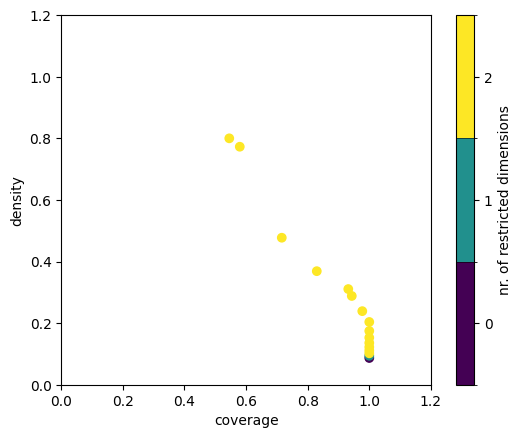

In [19]:
# === Pooling hurts: delta > 0 ===
y = delta > 0.00

print(f"Target scenarios: {y.sum()} / {len(y)} ({y.mean():.1%})")
p_box3 = prim.Prim(x, y, threshold=0.5)
box3 = p_box3.find_box()
box3.show_tradeoff()
plt.show()


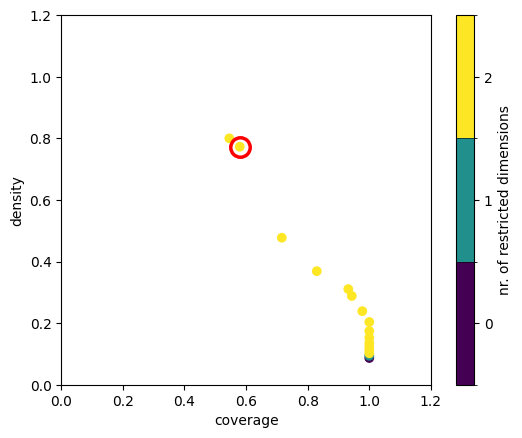

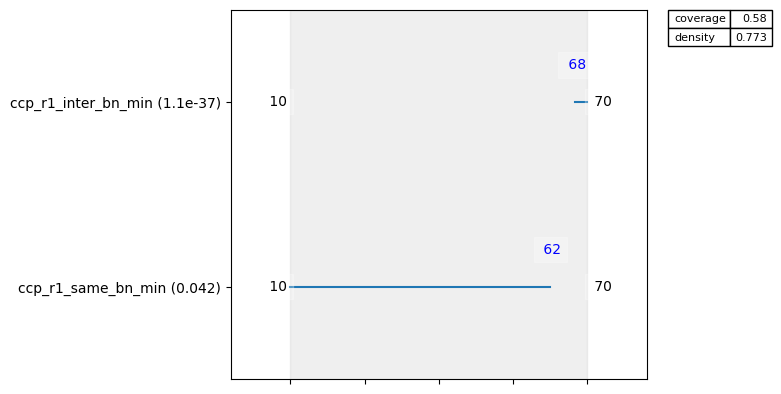

In [27]:
STEP_3 = 14   # e.g. 10, 15, 20

if STEP_3 is not None:
    box3.select(STEP_3)
show_tradeoff_highlighted(box3, step=STEP_3)

box3.inspect(style="graph")
plt.show()


In [28]:
box3.inspect()


coverage     0.579545
density      0.772727
id          14.000000
k           51.000000
mass         0.065089
mean         0.772727
n           66.000000
res_dim      2.000000
Name: 14, dtype: float64

                    box 14                              
                       min   max      qp value  qp value
ccp_r1_same_bn_min    10.0  62.5           NaN  0.041656
ccp_r1_inter_bn_min   67.5  70.0  1.132913e-37       NaN


[None]

C:\Users\User\AppData\Local\Temp\ipykernel_7392\3598805638.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,


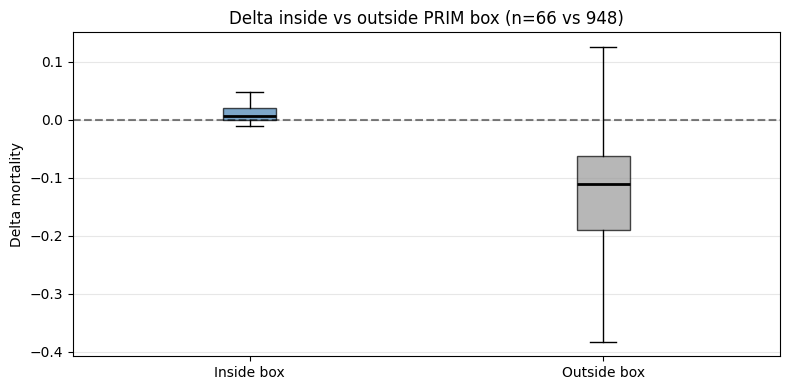

Inside:  n=66, helps=22.7%, hurts=77.3%, median=+0.0061, 95% CI [+0.0037, +0.0119]
Outside: n=948, helps=96.1%, hurts=3.9%, median=-0.1101


In [29]:
from scipy.stats import bootstrap as _bootstrap
_in = delta[box3.yi]
_out = np.delete(delta, box3.yi)

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot([_in, _out], labels=["Inside box", "Outside box"], patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=2))
bp["boxes"][0].set_facecolor("steelblue"); bp["boxes"][0].set_alpha(0.7)
bp["boxes"][1].set_facecolor("#999999"); bp["boxes"][1].set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title(f"Delta inside vs outside PRIM box (n={len(_in)} vs {len(_out)})")
plt.tight_layout()
plt.show()

_ci_in = _bootstrap((_in,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
print(f"Inside:  n={len(_in)}, helps={(_in<0).mean():.1%}, hurts={(_in>0).mean():.1%}, median={np.median(_in):+.4f}, 95% CI [{_ci_in.low:+.4f}, {_ci_in.high:+.4f}]")
print(f"Outside: n={len(_out)}, helps={(_out<0).mean():.1%}, hurts={(_out>0).mean():.1%}, median={np.median(_out):+.4f}")


In [ ]:
_idx = box3.yi
_l1, _l2 = "Both pooling", "Stovepipe"
_df1, _df2 = policy, stove

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
_c1, _c2 = "#e74c3c", "#2ecc71"
_w = 0.35

for _ai, (_col, _title) in enumerate([
    ("mortality_ccp_transport_T1", "CCP transport mortality"),
    ("mortality_r1_care_T1", "R1 care mortality"),
    ("death_rate_T1_BCAS", "Overall mortality"),
]):
    _d1 = _df1[_col].values[_idx]
    _d2 = _df2[_col].values[_idx]
    _bp1 = axes[_ai].boxplot([_d1], positions=[-_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp2 = axes[_ai].boxplot([_d2], positions=[_w/2], widths=_w*0.8, patch_artist=True,
                              showfliers=False, medianprops=dict(color="black", linewidth=2))
    _bp1["boxes"][0].set_facecolor(_c1); _bp1["boxes"][0].set_alpha(0.7)
    _bp2["boxes"][0].set_facecolor(_c2); _bp2["boxes"][0].set_alpha(0.7)
    axes[_ai].set_xticks([0])
    axes[_ai].set_xticklabels([f"Inside box\nn={len(_idx)}"])
    axes[_ai].set_title(_title)
    axes[_ai].set_ylabel("Mortality rate")
    axes[_ai].grid(True, alpha=0.3, axis="y")
    for _bp, _xp in [(_bp1, -_w/2), (_bp2, _w/2)]:
        _med = _bp["medians"][0].get_ydata()[0]
        axes[_ai].text(_xp, _med, f"  {_med:.4f}", ha="left", fontsize=8, fontweight="bold", va="bottom")

axes[0].legend([_bp1["boxes"][0], _bp2["boxes"][0]], [_l1, _l2], loc="upper right")
plt.suptitle(f"Mortality inside PRIM box (n={len(_idx)})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1"]:
    _f1 = (_df1[_col].values[_idx] > 0).mean()
    _f2 = (_df2[_col].values[_idx] > 0).mean()
    print(f"  {_col}: {_l1}={_f1:.1%}, {_l2}={_f2:.1%}")

from scipy.stats import bootstrap as _bootstrap
print(f"\nMedian mortality with 95% CI inside PRIM box (n={len(_idx)}):")
for _col in ["mortality_ccp_transport_T1", "mortality_r1_care_T1", "death_rate_T1_BCAS"]:
    _vals = _df1[_col].values[_idx]
    if len(set(_vals)) > 1:
        _ci = _bootstrap((_vals,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} CI=[{_ci.low:.4f}, {_ci.high:.4f}]")
    else:
        print(f"  {_col}: {_l1} median={np.median(_vals):.4f} (constant)")
    _vals2 = _df2[_col].values[_idx]
    if len(set(_vals2)) > 1:
        _ci2 = _bootstrap((_vals2,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} CI=[{_ci2.low:.4f}, {_ci2.high:.4f}]")
    else:
        print(f"  {_col}: {_l2} median={np.median(_vals2):.4f} (constant)")


## Summary: delta across PRIM boxes (helps / indifferent / hurts)


In [ ]:
from scipy.stats import bootstrap as _bootstrap

_d1 = delta[box1.yi]
_d2 = delta[box2.yi]
_d3 = delta[box3.yi]

fig, ax = plt.subplots(figsize=(10, 5))
bp = ax.boxplot([_d1, _d2, _d3], labels=["Helps (box1)", "Indifferent (box2)", "Hurts (box3)"],
                patch_artist=True, showfliers=False, medianprops=dict(color="black", linewidth=2))
colors = ["#2ecc71", "#f39c12", "#e74c3c"]
for b, c in zip(bp["boxes"], colors):
    b.set_facecolor(c); b.set_alpha(0.7)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_ylabel("Delta mortality")
ax.grid(True, alpha=0.3, axis="y")
plt.title("Delta distribution across PRIM boxes")
plt.tight_layout()
plt.show()

for bname, _d in [("Helps", _d1), ("Indifferent", _d2), ("Hurts", _d3)]:
    if len(set(_d)) > 1:
        _ci = _bootstrap((_d,), np.median, confidence_level=0.95, n_resamples=9999, method='percentile').confidence_interval
        print(f"{bname:<12} n={len(_d):>5}, helps={(_d<0).mean():>5.1%}, hurts={(_d>0).mean():>5.1%}, median={np.median(_d):+.4f}, 95% CI [{_ci.low:+.4f}, {_ci.high:+.4f}]")
    else:
        print(f"{bname:<12} n={len(_d):>5}, helps={(_d<0).mean():>5.1%}, hurts={(_d>0).mean():>5.1%}, median={np.median(_d):+.4f}")
